# Figure 2e. Share of *cis* + *trans* heritability explained by *trans* annotations

For each trait, the ratio of S-LDSC heritability captured by the *trans* annotation to that captured by the combined *cis* + *trans* annotation. The numerator is either TransMap-eGene + local (*trans*-eGene and *trans*-eProgram QTL) or TransMap-eGene alone. Error bars are ratio ± 1 SE (delta method, treating the two h² estimates as independent), as in the original figure code. Dashed line: ratio = 0.5.

Input: `data/Figure_2e_h2_ratio.rds`.

In [1]:
library(ggplot2)
library(patchwork)
res <- readRDS("data/Figure_2e_h2_ratio.rds")
head(res)
table(res$category, res$numerator)

,category,trait,trait_label,numerator,ratio,se
,<chr>,<chr>,<chr>,<fct>,<dbl>,<dbl>
1,Neurological Disorder & Aging Biomarker,AD_Bellenguez_buildGRCh38_munged.parquet,Alzheimer's Disease,TransMap-eGene + local,0.5855670,0.08158947
2,Neurological Disorder & Aging Biomarker,ALS-Rheenen-2021.GCST90027164_buildGRCh37,Amyotrophic Lateral Sclerosis,TransMap-eGene + local,0.5075446,0.11580926
3,Neurological Disorder & Aging Biomarker,PASS_Autism,Autism,TransMap-eGene + local,0.9156843,0.17771668
4,Neurological Disorder & Aging Biomarker,PASS_BipolarDisorder_Ruderfer2018,Bipolar Disorder,TransMap-eGene + local,0.7217115,0.08142790
5,Neurological Disorder & Aging Biomarker,PASS_MDD_Wray2018,Major Depressive Disorder,TransMap-eGene + local,0.9236948,0.11779237
6,Neurological Disorder & Aging Biomarker,PASS_Multiple_sclerosis,Multiple Sclerosis,TransMap-eGene + local,0.2003106,0.17903170


                                         
                                          TransMap-eGene + local TransMap-eGene
  Brain Imaging Endophenotypes                                17             17
  Neurological Disorder & Aging Biomarker                     11             11

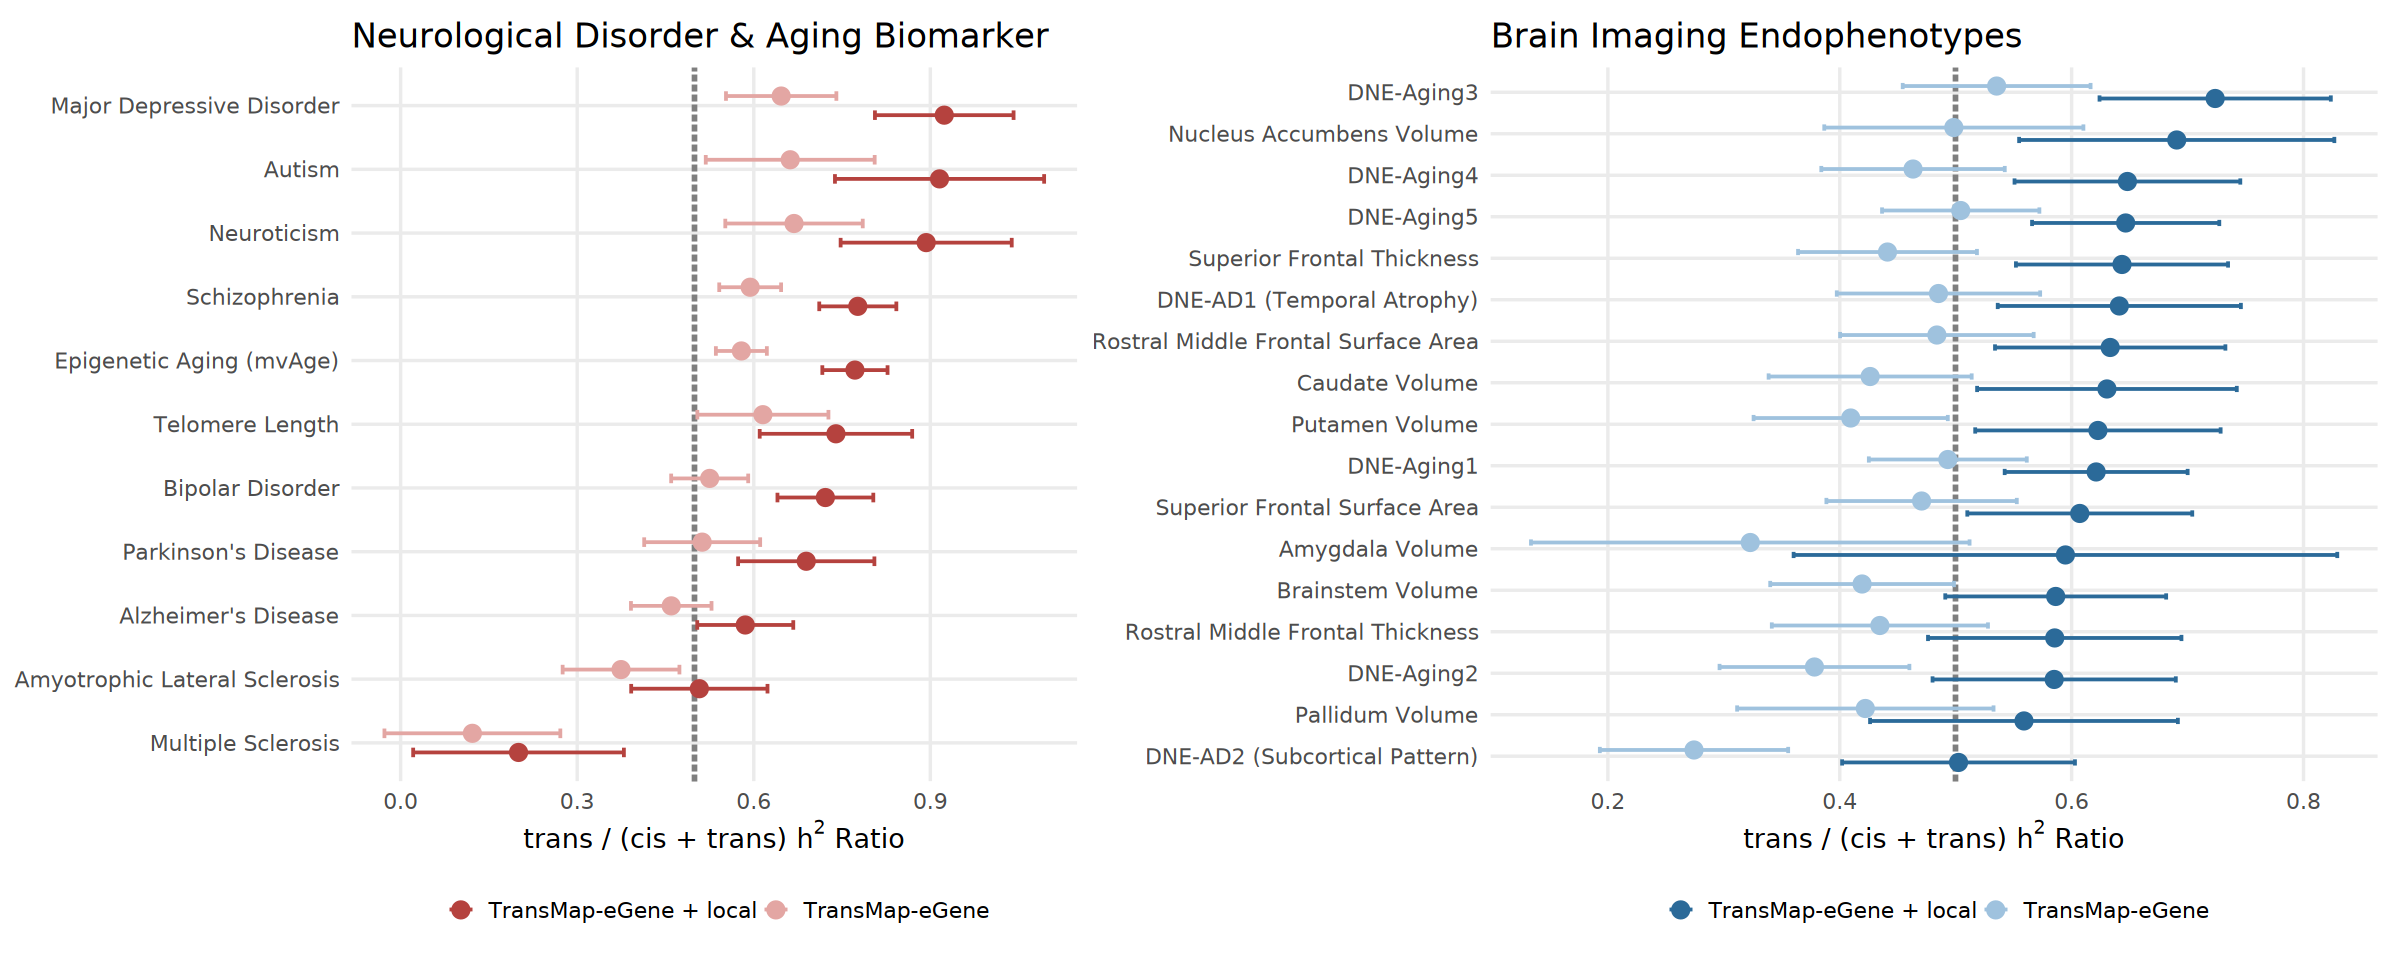

In [2]:
make_forest <- function(cat, colors) {
  d <- res[res$category == cat, ]
  ord <- d[d$numerator == "TransMap-eGene + local", ]
  d$trait_label <- factor(d$trait_label, levels = ord$trait_label[order(ord$ratio)])
  ggplot(d, aes(x = ratio, y = trait_label, colour = numerator)) +
    geom_vline(xintercept = 0.5, linetype = "longdash", colour = "grey50", linewidth = 1.2) +
    geom_errorbar(aes(xmin = ratio - se, xmax = ratio + se), width = 0.3, orientation = "y", linewidth = 0.8,
                   position = position_dodge(width = 0.6)) +
    geom_point(size = 4, position = position_dodge(width = 0.6)) +
    scale_colour_manual(values = colors) +
    labs(x = expression("trans / (cis + trans)" ~ h^2 ~ "Ratio"), y = NULL, colour = NULL, title = cat) +
    theme_minimal(base_size = 16) +
    theme(plot.title = element_text(size = 20), legend.position = "bottom",
          panel.grid.minor = element_blank())
}

p_neuro <- make_forest("Neurological Disorder & Aging Biomarker",
                       c("TransMap-eGene + local" = "#B5423E", "TransMap-eGene" = "#E3A6A3"))
p_image <- make_forest("Brain Imaging Endophenotypes",
                       c("TransMap-eGene + local" = "#2B6A99", "TransMap-eGene" = "#9FC2DE"))

options(repr.plot.width = 20, repr.plot.height = 8)
p_neuro + p_image + plot_layout(widths = c(0.45, 0.55))